# ML System Components — The Production Stack

A trained model is **5% of the work**. The other 95% is infrastructure.

When you train a model in a notebook you control everything: data loading, feature engineering, training, evaluation. In production, dozens of systems need to work together reliably, 24/7, at scale. This notebook maps that landscape.

**What you will understand after this notebook:**
- The five layers of an ML production stack and what lives in each
- Why feature stores exist and what problem they solve
- How model registries work and why teams use them
- The four serving patterns and when to use each
- What ML monitoring actually monitors (it is not just accuracy)

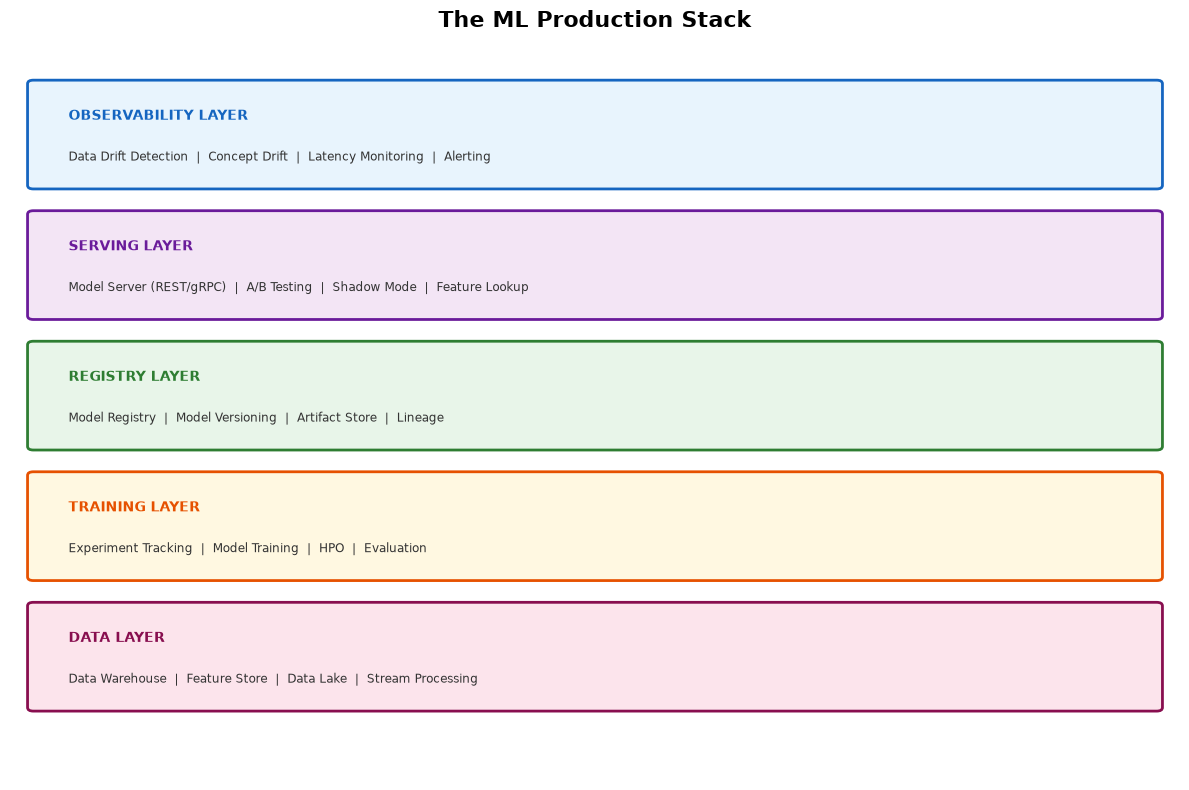

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# ── The 5-Layer ML Production Stack ──────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 8))
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.axis('off')
ax.set_title('The ML Production Stack', fontsize=16, fontweight='bold', pad=20)

layers = [
    (0.2, 8.2, 9.6, 1.4, '#E8F4FD', '#1565C0', 'OBSERVABILITY LAYER',
     'Data Drift Detection  |  Concept Drift  |  Latency Monitoring  |  Alerting'),
    (0.2, 6.4, 9.6, 1.4, '#F3E5F5', '#6A1B9A', 'SERVING LAYER',
     'Model Server (REST/gRPC)  |  A/B Testing  |  Shadow Mode  |  Feature Lookup'),
    (0.2, 4.6, 9.6, 1.4, '#E8F5E9', '#2E7D32', 'REGISTRY LAYER',
     'Model Registry  |  Model Versioning  |  Artifact Store  |  Lineage'),
    (0.2, 2.8, 9.6, 1.4, '#FFF8E1', '#E65100', 'TRAINING LAYER',
     'Experiment Tracking  |  Model Training  |  HPO  |  Evaluation'),
    (0.2, 1.0, 9.6, 1.4, '#FCE4EC', '#880E4F', 'DATA LAYER',
     'Data Warehouse  |  Feature Store  |  Data Lake  |  Stream Processing'),
]

for x, y, w, h, fc, ec, title, items in layers:
    rect = mpatches.FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.05',
                                    facecolor=fc, edgecolor=ec, linewidth=2)
    ax.add_patch(rect)
    ax.text(x + 0.3, y + h - 0.35, title, fontsize=10, fontweight='bold', color=ec, va='top')
    ax.text(x + 0.3, y + 0.3, items, fontsize=8.5, color='#333333', va='bottom')

plt.tight_layout()
plt.show()

## 1. Feature Store — Single Source of Truth for Features

**The problem:** During training you compute features from historical data in batch. During serving, you need those same features for a live request — but now you only have the current moment, not history. If you recompute features differently, your model sees a different distribution than it was trained on. This is called **training-serving skew** and it silently kills model performance.

**The solution:** A feature store decouples feature computation from model training and serving.

| Store | Purpose | Latency | Example |
|-------|---------|---------|--------|
| **Offline store** | Historical features for training | Minutes | S3, BigQuery, Hive |
| **Online store** | Latest feature values for serving | <10ms | Redis, DynamoDB, Cassandra |

Both stores are populated by the same feature pipeline — guaranteeing consistency.

In [2]:
from dataclasses import dataclass, field
from typing import Dict, List, Optional
import pandas as pd
import numpy as np

@dataclass
class FeatureStore:
    """Minimal feature store illustrating offline + online stores."""
    _offline: pd.DataFrame = field(default_factory=pd.DataFrame)  # historical
    _online: Dict[str, Dict] = field(default_factory=dict)         # latest per entity

    def materialize(self, df: pd.DataFrame, entity_col: str = 'user_id'):
        """Compute features once; write to both stores."""
        self._offline = df.copy()
        # Online store: keep only latest row per entity
        self._online = df.groupby(entity_col).last().to_dict(orient='index')
        print(f"Materialized {len(df)} rows → offline store")
        print(f"Materialized {len(self._online)} entities → online store")

    def get_training_features(self, start: str, end: str) -> pd.DataFrame:
        """Training: fetch historical window (offline store)."""
        mask = (self._offline['event_ts'] >= start) & (self._offline['event_ts'] <= end)
        return self._offline[mask]

    def get_online_features(self, entity_id: str) -> Optional[Dict]:
        """Serving: fetch latest features for one entity (online store, <10ms)."""
        return self._online.get(entity_id)


# Demo
np.random.seed(42)
n = 200
demo_data = pd.DataFrame({
    'user_id':        [f'u{i%50:03d}' for i in range(n)],
    'event_ts':       pd.date_range('2024-01-01', periods=n, freq='1h').astype(str),
    'session_count':  np.random.randint(1, 50, n),
    'avg_spend':      np.random.uniform(10, 500, n).round(2),
    'days_inactive':  np.random.randint(0, 30, n),
})

fs = FeatureStore()
fs.materialize(demo_data)

print("\n[Training] Fetching 7-day window:")
print(fs.get_training_features('2024-01-01', '2024-01-07').shape)

print("\n[Serving] Real-time lookup for user u001:")
print(fs.get_online_features('u001'))

Materialized 200 rows → offline store
Materialized 50 entities → online store

[Training] Fetching 7-day window:
(144, 5)

[Serving] Real-time lookup for user u001:
{'event_ts': '2024-01-07 07:00:00', 'session_count': 49, 'avg_spend': 275.9, 'days_inactive': 11}


## 2. Model Registry — Git for Models

A model registry answers: *which model is in production right now, who deployed it, what data was it trained on, and can I roll it back?*

**Lifecycle stages:**
```
None → Staging → Production → Archived
```
(In MLflow these fixed stages are deprecated since 2.9; the same steps are expressed with aliases: register a version → `@challenger` → `@champion`; a version without an alias is archived.)

Transition conditions are enforced: you cannot move to Production without passing a metric threshold. You cannot delete a model that is currently serving traffic.

**MLflow is the de-facto standard:**

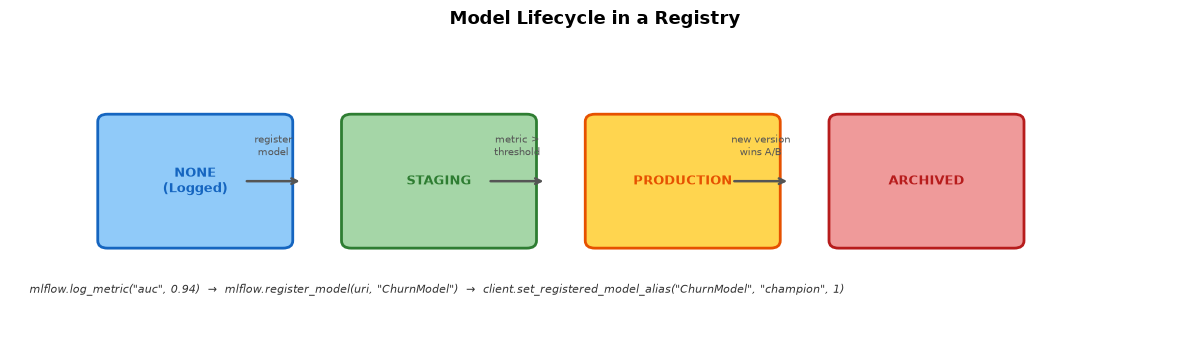

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe

# ── Model Lifecycle Diagram ───────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.set_xlim(0, 12)
ax.set_ylim(0, 4)
ax.axis('off')
ax.set_title('Model Lifecycle in a Registry', fontsize=13, fontweight='bold')

stages = [
    (1.0,  '#90CAF9', '#1565C0', 'NONE\n(Logged)'),
    (3.5,  '#A5D6A7', '#2E7D32', 'STAGING'),
    (6.0,  '#FFD54F', '#E65100', 'PRODUCTION'),
    (8.5,  '#EF9A9A', '#B71C1C', 'ARCHIVED'),
]
transitions = [
    (2.4,  'register\nmodel'),
    (4.9,  'metric >\nthreshold'),
    (7.4,  'new version\nwins A/B'),
]

for x, fc, ec, label in stages:
    rect = mpatches.FancyBboxPatch((x, 1.2), 1.8, 1.6,
                                    boxstyle='round,pad=0.1', facecolor=fc, edgecolor=ec, lw=2)
    ax.add_patch(rect)
    ax.text(x + 0.9, 2.0, label, ha='center', va='center', fontsize=9, fontweight='bold', color=ec)

for x, label in transitions:
    ax.annotate('', xy=(x + 0.6, 2.0), xytext=(x, 2.0),
                arrowprops=dict(arrowstyle='->', color='#555', lw=1.8))
    ax.text(x + 0.3, 2.35, label, ha='center', fontsize=7.5, color='#555')

# MLflow pseudocode
ax.text(0.2, 0.5,
    'mlflow.log_metric("auc", 0.94)  →  mlflow.register_model(uri, "ChurnModel")  →  '
    'client.set_registered_model_alias("ChurnModel", "champion", 1)',
    fontsize=8, color='#333', style='italic')

plt.tight_layout()
plt.show()

## 3. Model Serving Patterns

How predictions reach users depends on latency requirements, throughput, and infrastructure.

| Pattern | Latency | Throughput | When to Use |
|---------|---------|-----------|-------------|
| **REST API** | <100ms | Medium | User-facing features, external clients |
| **gRPC** | <10ms | High | Internal microservices, real-time bidding |
| **Batch** | Minutes–Hours | Very High | Nightly scoring, bulk recommendations |
| **Streaming** | <1s | High | Fraud detection, event-driven pipelines |

In [4]:
# Minimal FastAPI prediction endpoint — the standard REST pattern
# This is importable code; we don't start the server here

from pydantic import BaseModel
import time

class PredictionRequest(BaseModel):
    user_id: str
    features: dict

class PredictionResponse(BaseModel):
    user_id: str
    prediction: float
    model_version: str
    latency_ms: float

# In production this would be:
# from fastapi import FastAPI
# app = FastAPI()
# @app.post("/predict", response_model=PredictionResponse)
# async def predict(req: PredictionRequest):

def predict(req: PredictionRequest) -> PredictionResponse:
    start = time.perf_counter()

    # 1. Fetch online features from feature store
    # features = feature_store.get_online_features(req.user_id)

    # 2. Call model
    score = sum(req.features.values()) / len(req.features)  # mock

    # 3. Log prediction for monitoring
    # logger.info({"user_id": req.user_id, "score": score, "model": MODEL_VERSION})

    latency = (time.perf_counter() - start) * 1000
    return PredictionResponse(
        user_id=req.user_id,
        prediction=round(score, 4),
        model_version='churn-v3.2',
        latency_ms=round(latency, 2)
    )

# Test
req = PredictionRequest(user_id='u001', features={'session_count': 0.8, 'avg_spend': 0.6, 'days_inactive': 0.2})
resp = predict(req)
print(resp)

user_id='u001' prediction=0.5333 model_version='churn-v3.2' latency_ms=0.0


## 4. A/B Testing & Shadow Mode

You never deploy a new model directly to 100% of traffic. You test it.

- **A/B test:** Send X% of traffic to challenger. Measure business metrics (revenue, CTR, retention) — not just model metrics (AUC). Declare winner when statistically significant.
- **Shadow mode:** Challenger runs on all traffic but its predictions are never returned to users. Used to validate a model with zero risk before any A/B test.
- **Canary:** Small traffic slice (1–5%) deployed first. Watch error rates for 15 minutes before scaling up.

In [2]:
import hashlib
import random

class ABRouter:
    """Route requests between control and challenger models."""

    def __init__(self, challenger_pct: float = 0.10, shadow: bool = False):
        self.challenger_pct = challenger_pct  # 10% to challenger
        self.shadow = shadow                  # if True: challenger runs but never returned
        self._counts = {'control': 0, 'challenger': 0, 'shadow': 0}

    def route(self, user_id: str) -> str:
        # Sticky assignment: same user always hits same bucket
        # Stable hash: Python's built-in hash() of a str is randomized per process
        # (PYTHONHASHSEED), so it would NOT give the same bucket after a restart.
        bucket = int(hashlib.md5(user_id.encode("utf-8")).hexdigest(), 16) % 100
        if self.shadow:
            self._counts['shadow'] += 1
            return 'shadow'      # challenger runs, result discarded
        elif bucket < self.challenger_pct * 100:
            self._counts['challenger'] += 1
            return 'challenger'
        else:
            self._counts['control'] += 1
            return 'control'

router = ABRouter(challenger_pct=0.10)
users = [f'u{i:04d}' for i in range(1000)]
for u in users:
    router.route(u)

print("Traffic split over 1000 requests:")
for bucket, count in router._counts.items():
    print(f"  {bucket:>12}: {count:>4} ({count/10:.1f}%)")

Traffic split over 1000 requests:
       control:  898 (89.8%)
    challenger:  102 (10.2%)
        shadow:    0 (0.0%)


## 5. ML Monitoring — What Actually Breaks in Production

Models don't break with an error message. They silently degrade. Three failure modes:

1. **Data drift** — The input distribution shifted. Users changed behaviour. A new app version changed a feature. The model sees data unlike its training set.
2. **Concept drift** — P(y|x) changed. The relationship between features and labels shifted. A model trained before COVID predicting restaurant demand will fail post-COVID even with identical input features.
3. **Performance degradation** — Accuracy, precision, recall dropped. Often a downstream effect of the above. Hard to detect without labels (which arrive with delay).

In [6]:
from scipy import stats

def detect_drift(reference: np.ndarray, current: np.ndarray,
                 threshold: float = 0.05) -> dict:
    """Kolmogorov-Smirnov test for distribution shift on a single feature."""
    ks_stat, p_value = stats.ks_2samp(reference, current)
    return {
        'ks_statistic': round(ks_stat, 4),
        'p_value': round(p_value, 4),
        'drift_detected': p_value < threshold,
        'severity': 'HIGH' if ks_stat > 0.3 else 'MEDIUM' if ks_stat > 0.1 else 'LOW'
    }

np.random.seed(42)
# Training distribution
ref_session_count = np.random.exponential(scale=5, size=10_000)

print("=== Feature Drift Report ===")
scenarios = {
    'No drift (same distribution)':     np.random.exponential(scale=5,  size=500),
    'Moderate drift (shifted mean)':    np.random.exponential(scale=8,  size=500),
    'Severe drift (different shape)':   np.random.normal(loc=10, scale=3, size=500),
}
for name, current in scenarios.items():
    result = detect_drift(ref_session_count, current)
    flag = '🚨' if result['drift_detected'] else '✅'
    print(f"\n{flag} {name}")
    print(f"   KS={result['ks_statistic']}  p={result['p_value']}  "
          f"Drift={result['drift_detected']}  Severity={result['severity']}")

=== Feature Drift Report ===

✅ No drift (same distribution)
   KS=0.0278  p=0.8461  Drift=False  Severity=LOW

🚨 Moderate drift (shifted mean)
   KS=0.2053  p=0.0  Drift=True  Severity=MEDIUM



🚨 Severe drift (different shape)
   KS=0.64  p=0.0  Drift=True  Severity=HIGH


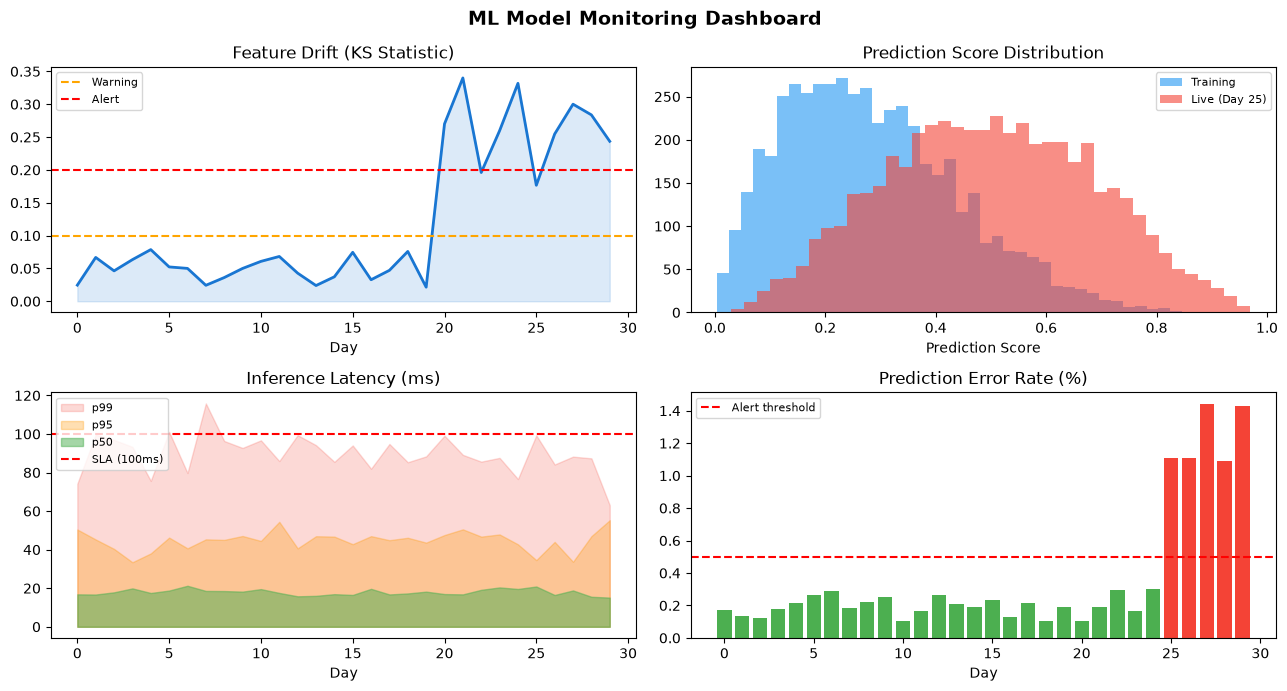

In [7]:
# ── Monitoring Dashboard ──────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
fig.suptitle('ML Model Monitoring Dashboard', fontsize=14, fontweight='bold')
days = np.arange(30)
np.random.seed(7)

# Panel 1: Feature drift score over time
drift = np.concatenate([np.random.uniform(0.02, 0.08, 20),
                         np.random.uniform(0.15, 0.35, 10)])
axes[0,0].plot(days, drift, color='#1976D2', lw=2)
axes[0,0].axhline(0.10, color='orange', ls='--', label='Warning')
axes[0,0].axhline(0.20, color='red', ls='--', label='Alert')
axes[0,0].fill_between(days, drift, alpha=0.15, color='#1976D2')
axes[0,0].set_title('Feature Drift (KS Statistic)'); axes[0,0].legend(fontsize=8)
axes[0,0].set_xlabel('Day')

# Panel 2: Prediction score distribution shift
ref_scores = np.random.beta(2, 5, 5000)
shifted_scores = np.random.beta(3, 3, 5000)
axes[0,1].hist(ref_scores, bins=40, alpha=0.6, color='#2196F3', label='Training')
axes[0,1].hist(shifted_scores, bins=40, alpha=0.6, color='#F44336', label='Live (Day 25)')
axes[0,1].set_title('Prediction Score Distribution'); axes[0,1].legend(fontsize=8)
axes[0,1].set_xlabel('Prediction Score')

# Panel 3: Latency percentiles
p50 = 18 + np.random.randn(30) * 2
p95 = 45 + np.random.randn(30) * 5
p99 = 90 + np.random.randn(30) * 10
axes[1,0].fill_between(days, p99, alpha=0.2, color='#F44336', label='p99')
axes[1,0].fill_between(days, p95, alpha=0.3, color='#FF9800', label='p95')
axes[1,0].fill_between(days, p50, alpha=0.5, color='#4CAF50', label='p50')
axes[1,0].axhline(100, color='red', ls='--', label='SLA (100ms)')
axes[1,0].set_title('Inference Latency (ms)'); axes[1,0].legend(fontsize=8)
axes[1,0].set_xlabel('Day')

# Panel 4: Error rate
error_rate = np.concatenate([np.random.uniform(0.001, 0.003, 25),
                              np.random.uniform(0.008, 0.015, 5)])
axes[1,1].bar(days, error_rate * 100, color=['#F44336' if e > 0.005 else '#4CAF50' for e in error_rate])
axes[1,1].axhline(0.5, color='red', ls='--', label='Alert threshold')
axes[1,1].set_title('Prediction Error Rate (%)'); axes[1,1].legend(fontsize=8)
axes[1,1].set_xlabel('Day')

plt.tight_layout()
plt.show()

## Key Takeaways

| Component | Problem It Solves | Key Tool |
|-----------|------------------|----------|
| **Feature Store** | Training-serving skew | Feast, Tecton, Hopsworks |
| **Model Registry** | Model versioning & governance | MLflow, W&B, Vertex AI |
| **Serving Layer** | Getting predictions to users | FastAPI, TorchServe, Triton |
| **A/B Testing** | Safe model rollout | Custom router + stats test |
| **Monitoring** | Detecting silent degradation | Evidently, WhyLabs, Arize |

**The ML engineering mindset:** Every component above exists because something went wrong in production at scale. Feature stores were invented because teams kept getting training-serving skew. Registries were invented because teams lost track of which model was deployed. Monitoring was invented because accuracy metrics never told you the model was broken until it was too late.

## Additional Learning Resources
- **Designing Machine Learning Systems** — Chip Huyen (O'Reilly, 2022)
- **Made With ML** — madewithml.com — free MLOps course by Goku Mohandas
- **Full Stack Deep Learning** — fullstackdeeplearning.com
- **Feature Store for ML** — featurestore.org
- **Evidently AI Blog** — evidentlyai.com/blog (ML monitoring patterns)